# 05 · FINAL: the chosen YOLOv8s, trained in full

The settings chosen on validation in notebook 04, trained for up to 50 epochs (early stopping after 10 epochs
without improvement). This is the model the pipeline and the app use. After training it is scored once on the test
set, followed by an error analysis: which objects it misses and what its false alarms are.

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## The chosen settings (from notebook 04)

In [2]:
import_outputs()          # final_config.json from the tuning notebook's output
choice = json.loads((RESULTS / "final_config.json").read_text())
cfg = dict(choice["config"])
rfs, IMGSZ, batch = cfg.pop("rfs", False), cfg.pop("imgsz"), cfg.pop("batch")
choice

imported: [] | missing: []


{'base': 'yolov8s.pt',
 'config': {'imgsz': 960, 'batch': 16, 'rfs': True, 'lr0': 0.002},
 'chosen_trial': 'E4e_lr002',
 'round1_kept': ['E4b_img960', 'E4c_rfs'],
 'val_primary': {'E4a_ref': 0.6696356606186296,
  'E4b_img960': 0.7865856385185234,
  'E4c_rfs': 0.6818422324177731,
  'E4d_combined': 0.7321179713766052,
  'E4e_lr002': 0.7786844472778629}}

## Data

In [3]:
tables = prepare_data()
data_yaml = write_rfs_list(tables)[0] if rfs else DATA / "kitti.yaml"

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543
RFS: 4699 training images -> 6157 per epoch


## Training

In [4]:
w, info = yolo_train("FINAL", choice["base"], data_yaml, imgsz=IMGSZ, epochs=50, batch=batch, **cfg)
info["settings"] = json.dumps(choice["config"])
info

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
training FINAL: yolov8s.pt, up to 50 epochs, imgsz 960, batch 16, changes: {'lr0': 0.002}
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti/train_rfs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, dis

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      7.37G      1.107     0.8588       1.05        150        960: 100% ━━━━━━━━━━━━ 385/385 2.5it/s 2:36
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 5.6it/s 6.9s
                   all       1239       7296      0.609      0.524      0.491      0.301

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50       7.7G      1.029     0.7368      1.016        144        960: 100% ━━━━━━━━━━━━ 385/385 2.5it/s 2:36
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 5.8it/s 6.8s
                   all       1239       7296      0.669      0.528      0.536      0.339

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      7.53G     0.9783     0.6764     0.9944        160        960: 100% ━━━━━━━━━━━━ 385/385 2.5it/s 2:36
                 Class     Images  Instances      Box(P 

{'model': 'yolov8s.pt',
 'imgsz': 960,
 'batch': 16,
 'max_epochs': 50,
 'epochs_run': 13,
 'best_epoch': 3,
 'train_hours': 0.624,
 'settings': '{"imgsz": 960, "batch": 16, "rfs": true, "lr0": 0.002}',
 'data': 'train_rfs.yaml',
 'ultralytics_val_mAP50': 0.53591,
 'ultralytics_val_mAP50_95': 0.33944}

## Training history

Blue = training, orange = validation; dashed = the epoch that was kept.

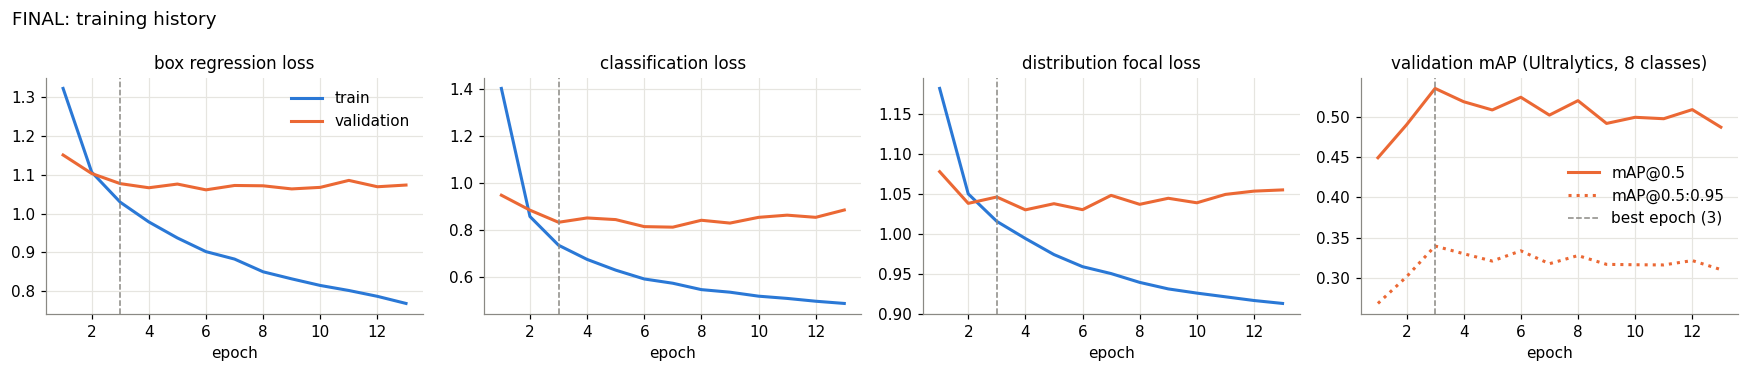

In [5]:
plot_yolo_history("FINAL")

## Validation

In [6]:
val, val_table, _ = evaluate_model("FINAL", "yolo", w, tables, "val", imgsz=IMGSZ)
headline(validation=val)

FINAL on val:   0%|          | 0/78 [00:00<?, ?it/s]

,validation
"Primary (Car/Ped/Cyc, Moderate)",0.758
Car,0.969
Pedestrian,0.762
Cyclist,0.545
Easy (3 classes),0.878
Hard (3 classes),0.708
Car AP@0.7,0.935
"mAP@0.5, all 8 classes",0.510
"mAP@0.5:0.95, all 8 classes",0.315


## Test set (once)

The model is now fixed: every choice above was made on validation. It is scored once on the test set, i.e. on drives
it has never seen.

In [7]:
test, test_table, test_preds = evaluate_model("FINAL", "yolo", WEIGHTS / "FINAL.pt", tables, "test", imgsz=IMGSZ)
headline(validation=val, test=test)

FINAL on test:   0%|          | 0/97 [00:00<?, ?it/s]

,validation,test
"Primary (Car/Ped/Cyc, Moderate)",0.758,0.799
Car,0.969,0.967
Pedestrian,0.762,0.797
Cyclist,0.545,0.631
Easy (3 classes),0.878,0.830
Hard (3 classes),0.708,0.780
Car AP@0.7,0.935,0.935
"mAP@0.5, all 8 classes",0.510,0.526
"mAP@0.5:0.95, all 8 classes",0.315,0.333


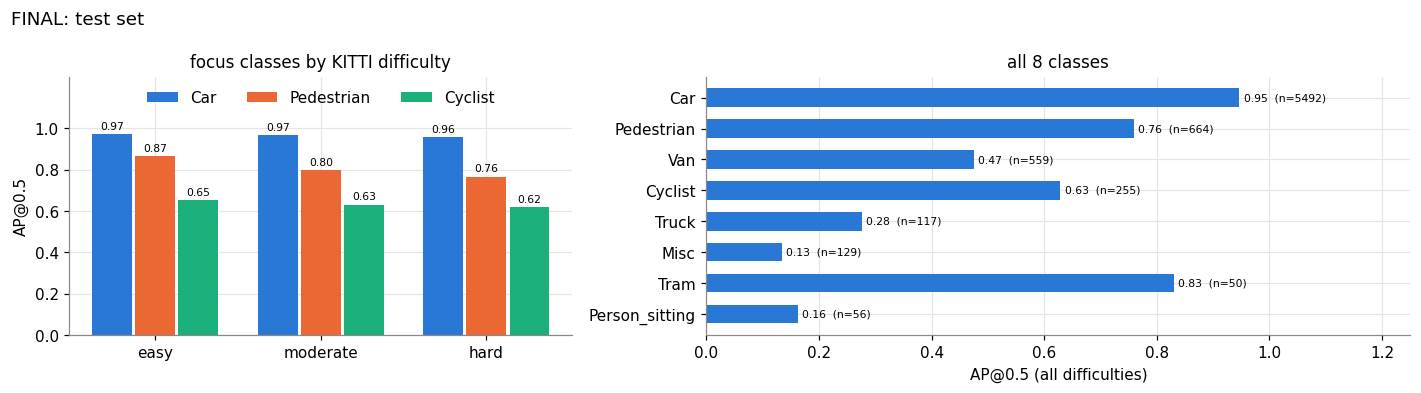

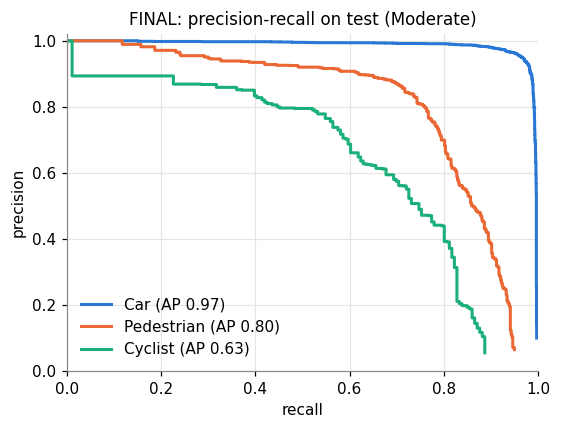

In [8]:
plot_per_class("FINAL", test_table, "test set")
plot_pr("FINAL", test_preds, tables, "test")

Ultralytics' own test evaluation, as a cross-check, with its normalised confusion matrix (rows: predicted class, columns: true class; *background* = missed objects / false alarms).

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,680 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5031.2±927.6 MB/s, size: 780.8 KB)
val: Scanning /tmp/kitti/labels/test... 1543 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1543/1543 181.0it/s 8.5s
val: New cache created: /tmp/kitti/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 5.2it/s 18.8s
                   all       1543       7322      0.559       0.54      0.531      0.341
Speed: 0.7ms preprocess, 7.4ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /tmp/runs/FINAL_test


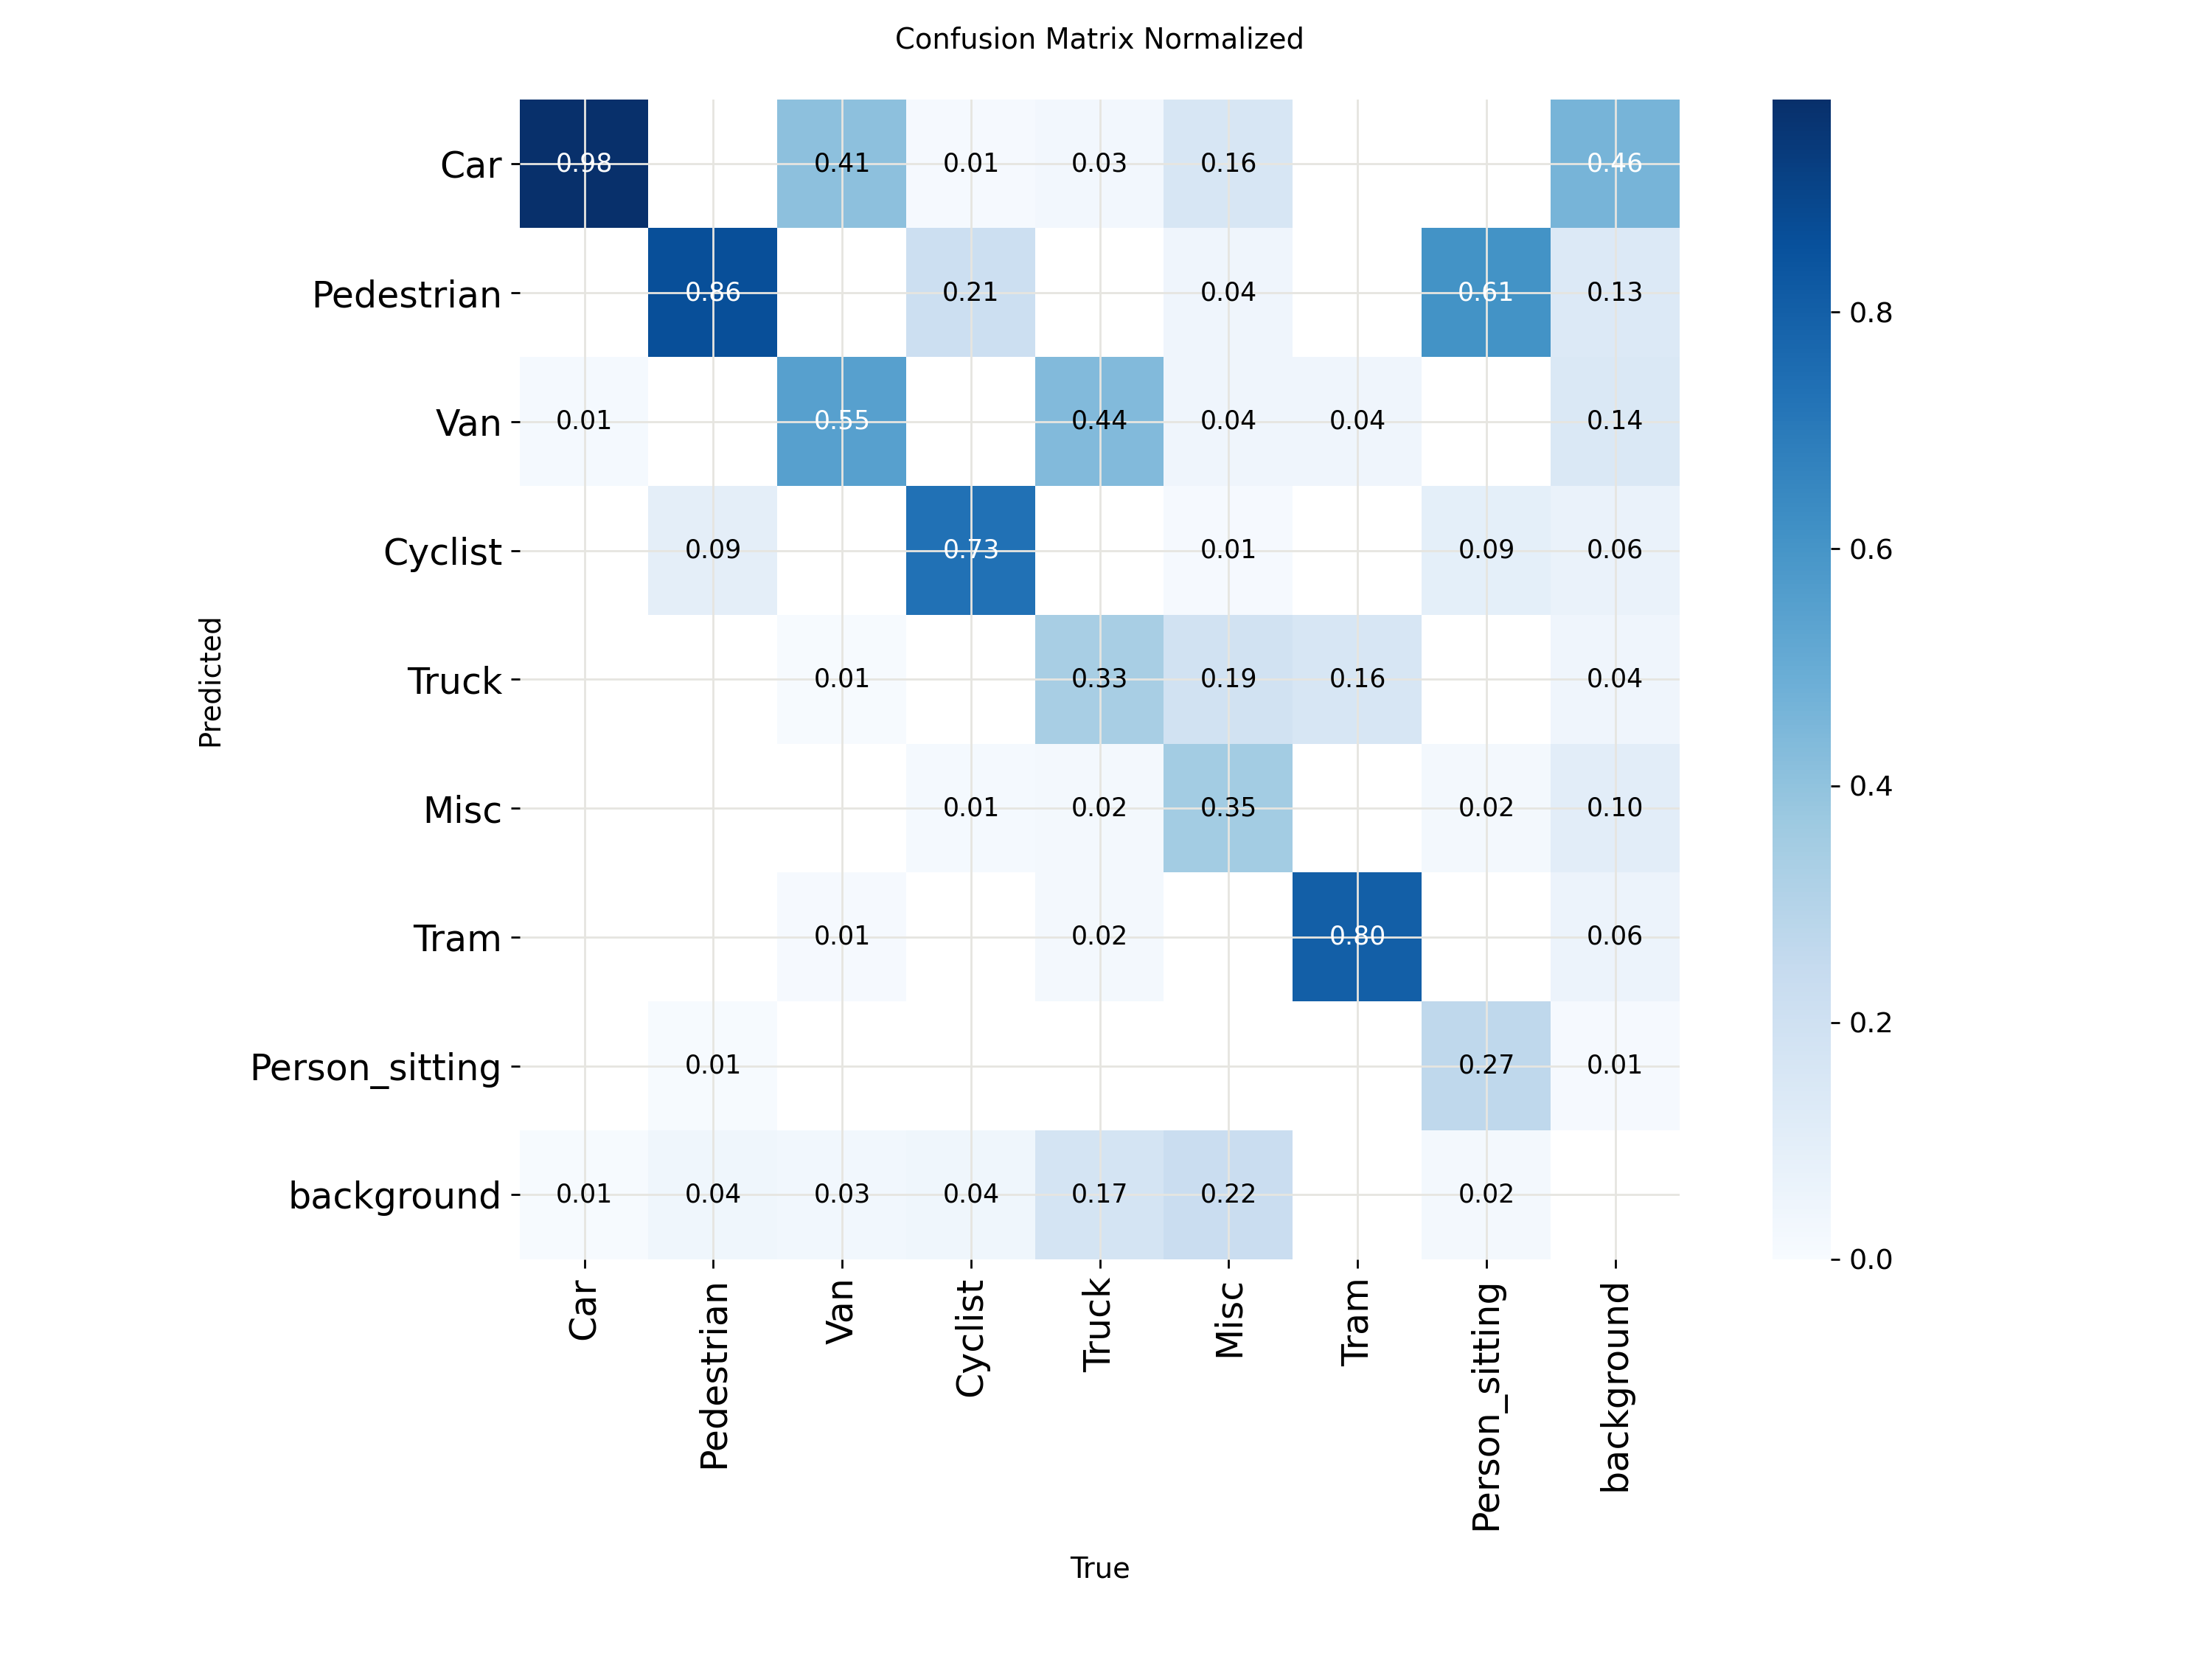

{'ultralytics_mAP50': 0.530932572075407,
 'ultralytics_mAP50_95': 0.3411582043432497}

In [9]:
ultra = ultralytics_test_report("FINAL", WEIGHTS / "FINAL.pt", IMGSZ)
ultra

A few test images (the same ones in every notebook): detections with score ≥ 0.4 against the ground truth.

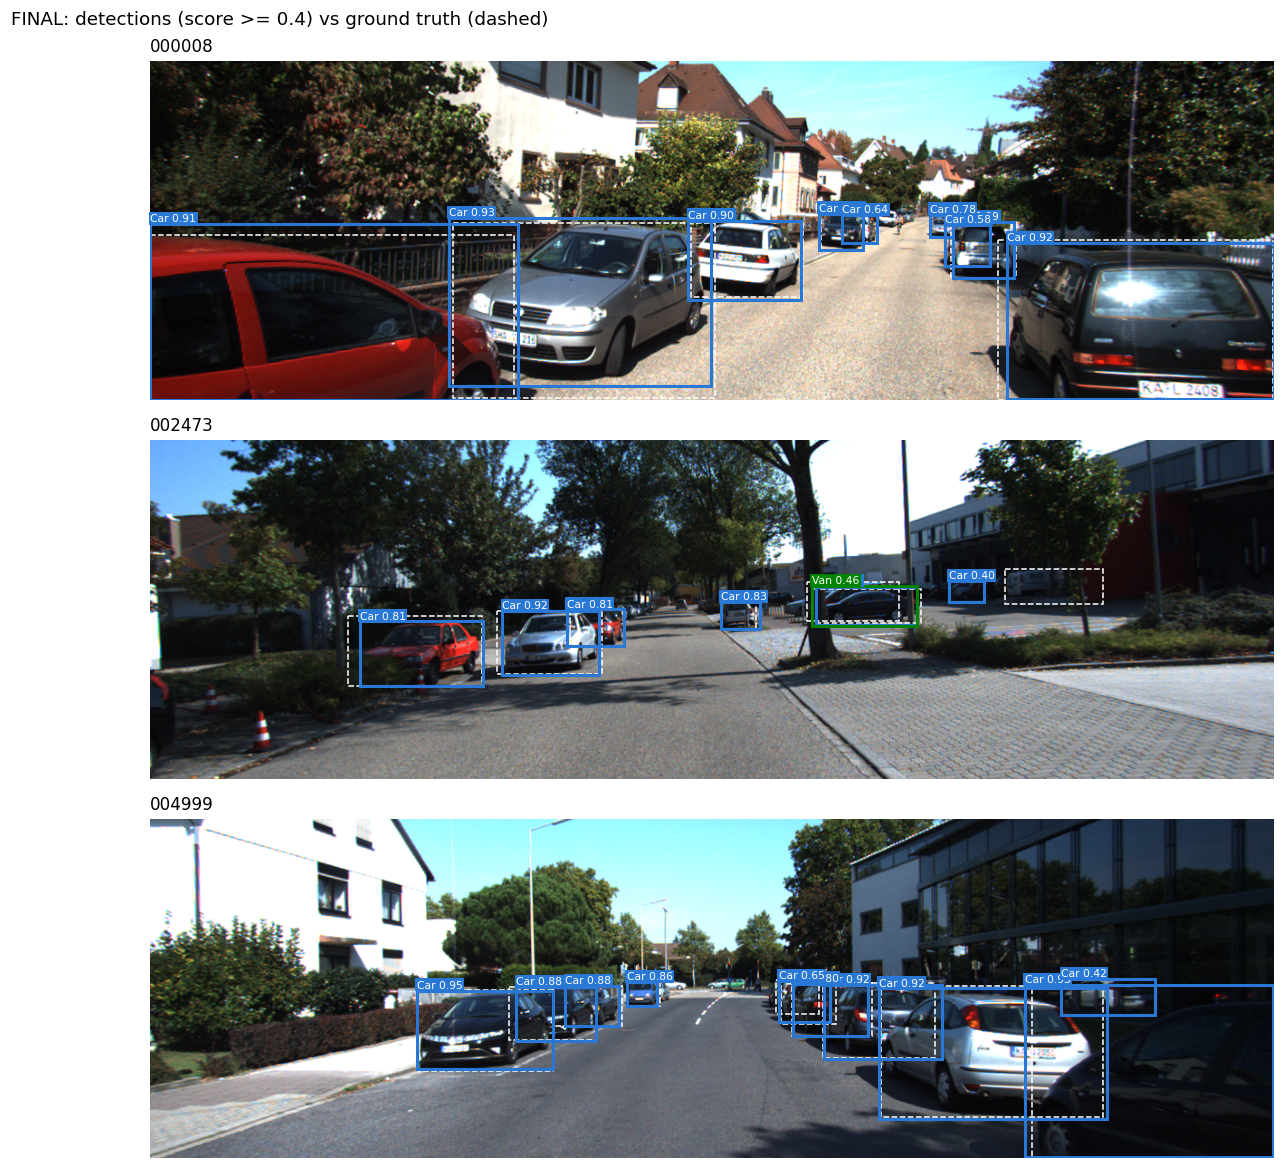

In [10]:
EXAMPLES = split_ids(tables[0], "test")[::max(1, len(split_ids(tables[0], "test")) // 3)][:3]
show_detections("FINAL", test_preds, tables, EXAMPLES)

## Observations

- **Primary metric: 0.758 validation, 0.799 test** (Car 0.967, Pedestrian 0.797, Cyclist 0.631). Against E2 this is
  **+0.083 on test**, and cyclists improve from 0.441 to 0.631.
- **Still below Faster R-CNN (0.854 test)**, mostly on cyclists (0.631 vs 0.779). The speed comparison in notebook 08
  decides which model the app uses.
- **Early overfitting again:** best epoch **3 of 13**, the same pattern as every model trained on the drive-grouped
  split.
- **What it misses (score ≥ 0.25):** recall is 95 % for cars, 77 % for pedestrians and 68 % for cyclists.
  Size matters most: only **21 % of 25–40 px pedestrians** and 41 % of 25–40 px cyclists are found, against 86 % and
  80 % above 80 px. Occlusion matters next: visible pedestrians 86 %, partly or largely occluded ones under 46 %.
- **What its false alarms are (3,271 at score ≥ 0.25):** 45 % fall **inside DontCare regions**, i.e. on real but
  unlabelled objects, so they are not truly errors. 22 % are poorly localised boxes on a real object, 19 % are the
  wrong class (most often Van and Car confused), and only 15 % are on background.

## Record

The experiment's row of the experiment log (`results/FINAL/record.json`).

In [11]:
rec = save_record("FINAL", "final model: settings chosen on validation in E4", "all", val=val, test=test, **info, **{f'test_{k}': v for k, v in ultra.items()})
pd.Series(rec).to_frame("value")

,value
exp_id,FINAL
description,final model: settings chosen on validation in E4
research_question,all
model,yolov8s.pt
imgsz,960
batch,16
max_epochs,50
epochs_run,13
best_epoch,3
train_hours,0.624


## Error analysis (test set, score ≥ 0.25)

At the threshold the app uses (0.25), which ground-truth objects are **missed**, broken down by size and occlusion,
and what kind of mistakes the **false alarms** are:

* *wrong class*: a box on a real object with the wrong label (e.g. Van called Car);
* *poor localisation*: right area, but IoU below 0.5;
* *background*: nothing there;
* *inside DontCare*: in an unlabelled region (not counted as an error by the KITTI rules).

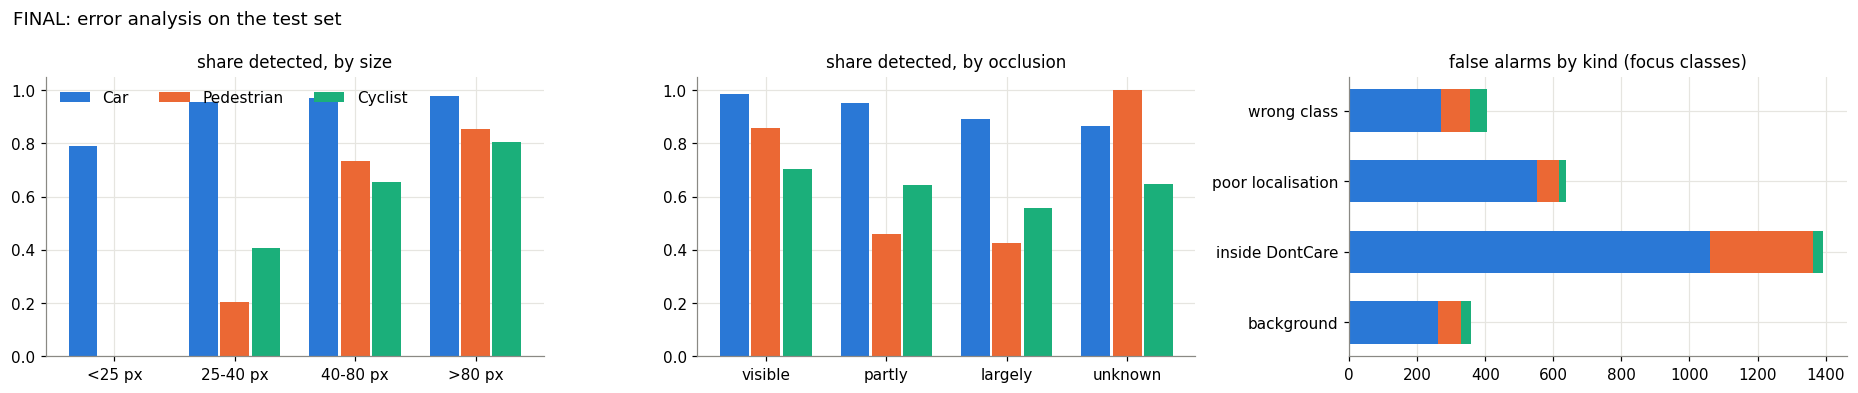

,share detected (all sizes)
type,
Car,0.950
Cyclist,0.682
Pedestrian,0.765


In [12]:
images, ann, ign = tables
p = test_preds[test_preds.score >= 0.25]
gt = ann[ann.image_id.isin(set(split_ids(images, "test")))].copy()
gt["bh"] = gt.y2 - gt.y1
gt["detected"] = False
fp, pb = [], {k: g for k, g in p.groupby("image_id")}
for iid, g in gt.groupby("image_id"):
    q = pb.get(iid)
    if q is None:
        continue
    ious = iou_matrix(q[["x1", "y1", "x2", "y2"]].to_numpy(float), g[["x1", "y1", "x2", "y2"]].to_numpy(float))
    hit = (ious >= 0.5) & (q["type"].to_numpy()[:, None] == g["type"].to_numpy()[None, :])
    gt.loc[g.index, "detected"] = hit.any(axis=0)
    in_dc = inside_fraction(q[["x1", "y1", "x2", "y2"]].to_numpy(float),
                            ign[ign.image_id == iid][["x1", "y1", "x2", "y2"]].to_numpy(float)) >= 0.5
    for j, r in enumerate(q.itertuples()):
        if hit[j].any():
            continue
        kind = ("inside DontCare" if in_dc[j] else "wrong class" if (ious[j] >= 0.5).any()
                else "poor localisation" if ious[j].max(initial=0) >= 0.1 else "background")
        fp.append({"image_id": iid, "type": r.type, "score": r.score, "fp_kind": kind})
fp = pd.DataFrame(fp)
gt["size"] = pd.cut(gt.bh, [0, 25, 40, 80, 1000], labels=["<25 px", "25-40 px", "40-80 px", ">80 px"])
gt["occlusion"] = gt.occluded.map({0: "visible", 1: "partly", 2: "largely", 3: "unknown"})
gt.to_csv(exp_dir("FINAL") / "test_gt_detected.csv", index=False)
fp.to_csv(exp_dir("FINAL") / "test_false_positives.csv", index=False)

foc = gt[gt["type"].isin(FOCUS)]
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
for a, col in zip(ax[:2], ["size", "occlusion"]):
    r = foc.pivot_table(index=col, columns="type", values="detected", aggfunc="mean", observed=False).reindex(columns=FOCUS)
    if col == "occlusion":
        r = r.reindex([o for o in ["visible", "partly", "largely", "unknown"] if o in r.index])
    x = np.arange(len(r))
    for j, c in enumerate(FOCUS):
        a.bar(x + (j - 1) * 0.26, r[c].values, 0.24, color=CLASS_C[c], label=c)
    a.set_xticks(x, r.index.astype(str)); a.set_ylim(0, 1.05); a.set_title(f"share detected, by {col}")
ax[0].legend(ncol=3, loc="upper left")
k = fp[fp.type.isin(FOCUS)].groupby(["fp_kind", "type"]).size().unstack(fill_value=0).reindex(columns=FOCUS, fill_value=0)
left = np.zeros(len(k))
for c in FOCUS:
    ax[2].barh(k.index, k[c].values, left=left, color=CLASS_C[c], label=c, height=0.6)
    left += k[c].values
ax[2].set_title("false alarms by kind (focus classes)")
fig.suptitle("FINAL: error analysis on the test set", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); fig.savefig(exp_dir("FINAL") / "figures" / "error_analysis.png", dpi=130); plt.show()
foc.groupby("type").detected.mean().round(3).to_frame("share detected (all sizes)")